[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_riskcontrib/BA_L3_riskcontrib.ipynb)

# BA_L3_riskcontrib: Bitcoin share of portfolio risk

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Euler risk contributions of Bitcoin in a 60/40 S&P 500/Treasuries (TLT) portfolio with Bitcoin weights from 0 to 10%: share of the portfolio volatility and of the historical ES 2.5%, daily simple returns on common trading days 2018 to 18 September 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** S&P 500 index (price index, no dividends), the iShares 20+ Year Treasury Bond ETF (TLT, adjusted close: distributions reinvested) and Bitcoin, on their common trading days from 2 January 2018 to 18 September 2026.
Daily **simple** returns $R_t = P_t/P_{t-1} - 1$, so that with daily rebalancing the portfolio return is exactly $w^\top R_t$.

**Method.** For weights $w$ and covariance matrix $\Sigma$, $\sigma_p = \sqrt{w^\top\Sigma w}$ splits by Euler's theorem into risk contributions
$$ \mathrm{RC}_i = \frac{w_i(\Sigma w)_i}{\sigma_p}, \qquad \sum_i \mathrm{RC}_i = \sigma_p . $$
For historical ES 2.5%: $\mathrm{RC}^{ES}_i = -\mathrm{E}[w_i R_i \mid R_p \le q_{2.5\%}(R_p)]$. The portfolio holds the S&P 500 and Treasuries in proportion 60/40 plus a Bitcoin weight $w_B$ from 0 to 10%.

**How to read.** Bitcoin's share of risk ($\mathrm{RC}_B/\sigma_p$, in %) against its weight; the dashed blue line is the weight itself: points above it mean Bitcoin carries more risk than money.

In [4]:
END = '2026-09-18'


def adjusted(sym, end):
    # adjusted close (distributions reinvested) from data/market/<sym>.csv
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['adjusted_close']
    return p[p > 0].loc[:end]


px = pd.concat({'S&P 500': daily('GSPC.INDX', END), 'Treasuries (TLT)': adjusted('TLT.US', END),
                'Bitcoin': daily('BTC-USD.CC', END)}, axis=1).dropna()
X = (100 * px.pct_change()).dropna().loc['2018-01-01':]          # daily simple returns, %
print(f'common days: {len(X)}, {X.index[0].date()} - {X.index[-1].date()}')

common days: 2190, 2018-01-02 - 2026-09-18


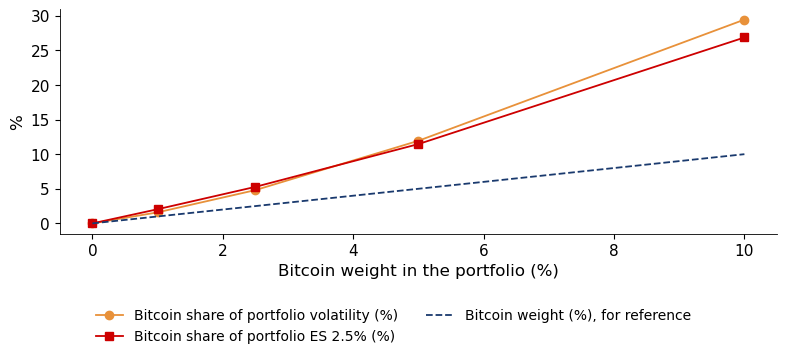

In [5]:
p25 = 0.025
S = X.cov().values
rows = {}
for wb in [0, 0.01, 0.025, 0.05, 0.10]:
    w = np.array([0.6 * (1 - wb), 0.4 * (1 - wb), wb])
    sp = np.sqrt(w @ S @ w)
    rc = w * (S @ w) / sp
    rp = X.values @ w
    tail = rp <= np.quantile(rp, p25)
    es = -rp[tail].mean()
    esc = -(X.values[tail] * w).mean(axis=0)
    rows[100 * wb] = {'volatility (% a year)': sp * np.sqrt(252), 'ES 2.5% (%, daily)': es,
                      'Bitcoin share of volatility (%)': 100 * rc[2] / sp, 'Bitcoin share of ES (%)': 100 * esc[2] / es + 0.0}
P_ = pd.DataFrame(rows).T
P_.index.name = 'Bitcoin weight (%)'

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(P_.index, P_['Bitcoin share of volatility (%)'], marker='o', color=BTC, label='Bitcoin share of portfolio volatility (%)')
ax.plot(P_.index, P_['Bitcoin share of ES (%)'], marker='s', color=RED, label='Bitcoin share of portfolio ES 2.5% (%)')
ax.plot(P_.index, P_.index, color=BLUE, ls='--', label='Bitcoin weight (%), for reference')
ax.set_xlabel('Bitcoin weight in the portfolio (%)'); ax.set_ylabel('%')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l3_riskcontrib')

**Key numbers** (as on the slide).

In [6]:
P_['Bitcoin share of volatility / weight'] = P_['Bitcoin share of volatility (%)'] / P_.index.to_series().replace(0, np.nan)
P_.round(2)

,volatility (% a year),"ES 2.5% (%, daily)",Bitcoin share of volatility (%),Bitcoin share of ES (%),Bitcoin share of volatility / weight
Bitcoin weight (%),,,,,
0.0,12.25,2.26,0.00,0.00,NaN
1.0,12.31,2.29,1.59,2.04,1.59
2.5,12.45,2.32,4.81,5.28,1.92
5.0,12.83,2.40,11.94,11.46,2.39
10.0,14.08,2.60,29.45,26.87,2.94
